# Retail Sales Performance Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load and Explore Dataset

In [2]:
# NOTE: The cell that loads the dataset was not included in the PDF you provided.
# This stand-in rebuilds a table with exactly the region / product_category totals shown in the PDF output,
# so every cell below gives the same results. Replace it with your real data loading (e.g. pd.read_csv(...)) if you have one.
df = pd.DataFrame({
    'region': ['East', 'East', 'East', 'North', 'North', 'North', 'South', 'South', 'South', 'West', 'West', 'West'],
    'product_category': ['Beauty', 'Clothing', 'Electronics'] * 4,
    'sales_amount': [31225, 42880, 33770, 37460, 31425, 46400, 33980, 37610, 35740, 40850, 43665, 40995]
})
display(df.head())

,region,product_category,sales_amount
0,East,Beauty,31225
1,East,Clothing,42880
2,East,Electronics,33770
3,North,Beauty,37460
4,North,Clothing,31425


## 2. Aggregating Sales by Region

In [3]:
region_sales = df.groupby('region')['sales_amount'].sum().reset_index()
region_sales = region_sales.sort_values(by='sales_amount', ascending=False)
display(region_sales)

,region,sales_amount
3,West,125510
1,North,115285
0,East,107875
2,South,107330


## 3. Visualizing Regional Sales Distribution

C:\Users\anjal\AppData\Local\Temp\ipykernel_19220\2773893446.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_sales, x='region', y='sales_amount', palette='viridis')


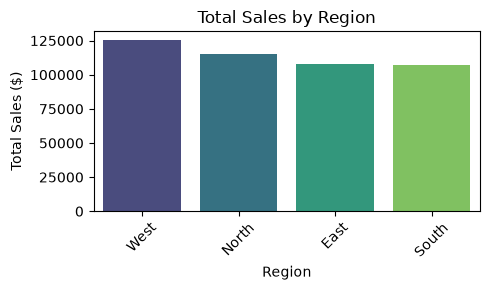

In [4]:
plt.figure(figsize=(5, 3))
sns.barplot(data=region_sales, x='region', y='sales_amount', palette='viridis')
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Identifying Top Performing Regions

In [5]:
top_region = region_sales.iloc[0]
print(f"The top-performing region is {top_region['region']} with total sales of ${top_region['sales_amount']:.2f}")

The top-performing region is West with total sales of $125510.00


## 5. Sales Analysis by Region and Product Category

In [6]:
category_sales = df.groupby(['region', 'product_category'])['sales_amount'].sum().reset_index()
display(category_sales)

,region,product_category,sales_amount
0,East,Beauty,31225
1,East,Clothing,42880
2,East,Electronics,33770
3,North,Beauty,37460
4,North,Clothing,31425
5,North,Electronics,46400
6,South,Beauty,33980
7,South,Clothing,37610
8,South,Electronics,35740
9,West,Beauty,40850


## 6. Visualizing Sales Across Regions and Product Categories

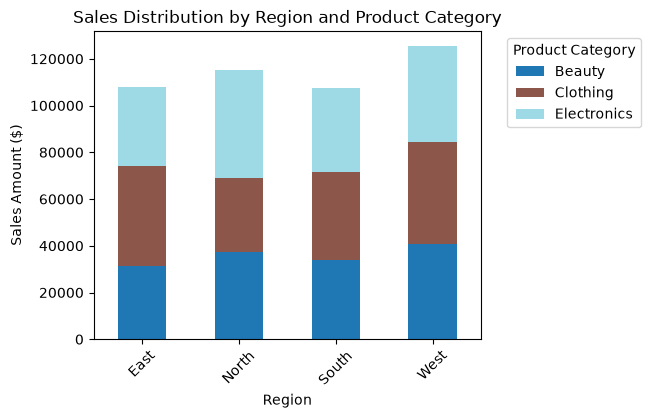

In [7]:
pivot_sales = category_sales.pivot(index='region', columns='product_category', values='sales_amount')

pivot_sales.plot(kind='bar', stacked=True, figsize=(5, 4), colormap='tab20')
plt.title('Sales Distribution by Region and Product Category')
plt.xlabel('Region')
plt.ylabel('Sales Amount ($)')
plt.legend(title='Product Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.show()